# Examen — Módulo 1: Preparación de datos
**Aprendizaje Supervisado · Evaluación de las sesiones 1–3** (EDA, preprocesamiento, ingeniería y selección de variables)

**Instrucciones**

- Trabajo **individual**. Duración sugerida: **120 minutos**. Material permitido: tus notas, la presentación y la documentación oficial de pandas, scikit-learn y matplotlib.
- Escribe tu nombre en la primera celda de código (`NOMBRE`).
- Sustituye cada `...` (marcado con ✏️) por tu código. En las preguntas con **“Respuesta:”**, escribe tu explicación en la celda de texto que sigue (editando la celda de Markdown).
- Antes de entregar, ejecuta **Kernel → Reiniciar y ejecutar todo**; el notebook debe correr de principio a fin sin errores.
- Los datos son simulados y se generan con semilla fija: tus resultados deben ser reproducibles.
- Se evalúa tanto el **código** como la **calidad de la justificación**. Las respuestas escritas deben ser breves y precisas.

| Parte | Tema | Puntos |
|---|---|---|
| I | Análisis exploratorio de datos | 30 |
| II | Preprocesamiento de datos | 35 |
| III | Ingeniería y selección de variables | 35 |
| | **Total** | **100** |


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder,
                                   OrdinalEncoder, PolynomialFeatures)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
                                       RFE, RFECV, SelectFromModel)
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

NOMBRE = "Christian Isaac Dzul Canul"        # ✏️ escribe tu nombre completo


In [2]:
# ---------------------------------------------------------------------------------------------
# Generadores de datos (NO los modifiques; no necesitas leerlos para resolver el examen)
# ---------------------------------------------------------------------------------------------
def genera_viviendas(n=1200, seed=2026):
    """Viviendas en venta en una ciudad (datos simulados). Precio en miles de pesos."""
    r = np.random.default_rng(seed)
    zona = r.choice(["Norte", "Centro", "Poniente", "Oriente", "Sur", "Costa"], n, p=[.30, .15, .22, .14, .17, .02])
    acab = r.choice(["Básico", "Medio", "Alto", "Premium"], n, p=[.30, .40, .22, .08])
    sup = np.exp(r.normal(np.log(110), .38, n)).round(0)
    rec = np.clip(np.round(sup / 45 + r.normal(0, .6, n)), 1, 6).astype(int)
    ant = np.clip(r.gamma(1.6, 9, n), 0, 70).round(0)
    dist = np.round(r.gamma(2.2, 3.2, n), 1)
    zef = pd.Series(zona).map({"Norte": .25, "Centro": .05, "Poniente": .10, "Oriente": -.20, "Sur": -.30, "Costa": .55}).values
    aef = pd.Series(acab).map({"Básico": 0, "Medio": .18, "Alto": .40, "Premium": .75}).values
    lp = 1.2 + .85 * np.log(sup) + zef + aef - .008 * ant - .035 * dist + .04 * rec + r.normal(0, .17, n)
    precio = (np.exp(lp) * 25).round(0)
    idx = r.choice(n, 10, replace=False)
    precio[idx] *= r.uniform(3.5, 6, 10)
    df = pd.DataFrame(dict(zona=zona, acabados=acab, superficie_m2=sup, recamaras=rec,
                           antiguedad_anios=ant, dist_centro_km=dist, precio_miles=precio.round(0)))
    pm = np.where(np.isin(zona, ["Sur", "Oriente"]), .22, .04)
    df.loc[r.random(n) < pm, "antiguedad_anios"] = np.nan
    df.loc[r.random(n) < .04, "superficie_m2"] = np.nan
    return df


def genera_biomarcadores(n=400, seed=7):
    """400 pacientes, 26 mediciones de laboratorio y un diagnóstico y ∈ {0, 1} (datos simulados)."""
    r = np.random.default_rng(seed)
    y = r.integers(0, 2, n)
    s = 2 * y - 1
    a = r.normal(0.9 * s, 1.0)
    b = 100 + 15 * r.normal(0.6 * s, 1.0)
    c = 0.02 * r.normal(0.8 * s, 1.0)
    cuad = np.where(y == 1, r.choice([-1, 1], n) * r.normal(1.6, .35, n), r.normal(0, .45, n))
    a_copia = a + r.normal(0, .15, n)
    casi = 5 + 1e-3 * r.normal(0, 1, n)
    ruido = r.normal(0, 1, (n, 20)) * r.choice([1, 1, 1, 10, 50], 20)
    cols = {"lin_a": a, "lin_b": b, "lin_c": c, "cuad": cuad, "lin_a_copia": a_copia, "casi_const": casi}
    for i in range(20):
        cols[f"ruido_{i + 1:02d}"] = ruido[:, i]
    return pd.DataFrame(cols), pd.Series(y, name="y")


---
## Parte I — Análisis exploratorio de datos (30 puntos)

Trabajarás con `viv`: **1 200 viviendas en venta** de una ciudad (datos simulados).
Variables: `zona` y `acabados` (categóricas; `acabados` es ordinal: Básico < Medio < Alto < Premium), `superficie_m2`, `recamaras`,
`antiguedad_anios`, `dist_centro_km` y el objetivo `precio_miles` (miles de pesos). Hay valores faltantes.

In [3]:
viv = genera_viviendas()
NUM = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km", "precio_miles"]
print(viv.shape)
viv.head()

(1200, 7)


,zona,acabados,superficie_m2,recamaras,antiguedad_anios,dist_centro_km,precio_miles
0,Norte,Medio,74.0,2,25.0,8.1,4289.0
1,Poniente,Medio,166.0,4,14.0,9.4,7465.0
2,Poniente,Premium,211.0,4,7.0,2.1,16996.0
3,Centro,Medio,153.0,4,30.0,3.4,6301.0
4,Centro,Básico,101.0,2,0.0,9.5,4444.0


### Pregunta I.1 · Asimetría y curtosis  *(4 pts)*

Calcula la **asimetría** y la **curtosis (excedente)** de las cinco variables numéricas `NUM` y guarda en `mas_asimetrica` el *nombre* de la variable con mayor asimetría.

In [4]:
asim = viv[NUM].skew()              # ✏️ Series con la asimetría de cada variable de NUM
curt = viv[NUM].kurt()              # ✏️ Series con la curtosis excedente (pandas ya resta 3)
mas_asimetrica = asim.idxmax()      # ✏️ nombre (str) de la variable más asimétrica

print(pd.DataFrame({"asimetría": asim, "curtosis": curt}).round(2))
print("Más asimétrica:", mas_asimetrica)

                  asimetría  curtosis
superficie_m2          1.00      1.42
recamaras              0.57      0.10
antiguedad_anios       1.41      2.36
dist_centro_km         1.16      1.87
precio_miles           3.38     22.95
Más asimétrica: precio_miles


### Pregunta I.2 · Interpretar la forma de `precio_miles`  *(3 pts)*

Observa la media y la mediana del precio y su histograma. En **3 a 5 líneas**: ¿qué forma tiene la distribución según la asimetría y la curtosis? ¿Qué medida de centro describiría mejor un precio “típico” y por qué?

media = 5,271   mediana = 4,504


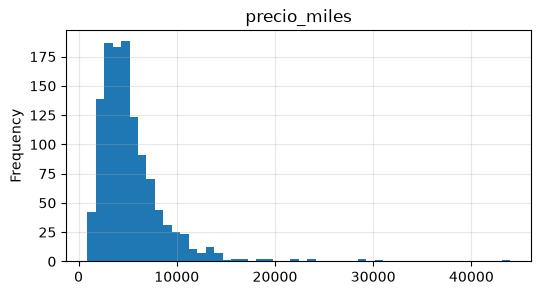

In [5]:
print(f"media = {viv.precio_miles.mean():,.0f}   mediana = {viv.precio_miles.median():,.0f}")
viv.precio_miles.plot.hist(bins=50, figsize=(6, 3), title="precio_miles");

**Respuesta:**

La distribución del precio es asimétrica a la derecha (asimetría = 3.38 ) y con colas muy pesadas (curtosis excedente = 22.9, frente a 0 de una normal): la mayoría de las viviendas se concentra en precios medios y unas pocas tienen precios muy altos. Por eso la media (5,271) queda por encima de la mediana (4,504). Para describir un precio “típico” usaría la mediana, porque es robusta, no se deja arrastrar por los pocos precios extremos, mientras que la media sí.

### Pregunta I.3 · Regla del IQR  *(5 pts)*

Escribe la función `atipicos_iqr(s, k=1.5)` que, dada una Series `s`, devuelva una Series booleana que marque como atípicos los valores fuera de $[Q_1 - k\,\mathrm{IQR},\; Q_3 + k\,\mathrm{IQR}]$ (ignora los `NaN`). Después cuenta los atípicos de cada variable de `NUM`.

In [6]:
def atipicos_iqr(s, k=1.5): # ✏️ calcula Q1, Q3, IQR y devuelve la máscara booleana
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])          #cuartiles
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)   #True = atípico


n_atip = {c: int(atipicos_iqr(viv[c]).sum()) for c in NUM}     # ✏️ dict {variable: número de atípicos}
print(n_atip)

{'superficie_m2': 20, 'recamaras': 78, 'antiguedad_anios': 37, 'dist_centro_km': 25, 'precio_miles': 57}


### Pregunta I.4 · El logaritmo y los atípicos  *(4 pts)*

Crea `log_precio = np.log(viv.precio_miles)`, calcula su asimetría y cuántos atípicos marca la regla del IQR. Luego responde en **3 a 4 líneas**: ¿la transformación resolvió el problema de los atípicos? Entre eliminarlos, dejarlos o transformarlos, ¿qué harías con las viviendas más caras y por qué? (Recuerda cómo se generó el dato: hay viviendas con precios muy superiores al de su tipo.)

In [7]:
log_precio = np.log(viv.precio_miles)                   # ✏️
asim_log = log_precio.skew()                             # ✏️ asimetría de log_precio
n_atip_log = int(atipicos_iqr(log_precio).sum())         # ✏️ atípicos de log_precio según la regla del IQR
print(f"asimetría: {asim_log:.2f}   atípicos: {n_atip_log}")

asimetría: 0.22   atípicos: 14


**Respuesta:**

El logaritmo **mejora mucho** la forma (asimetría de 3.38 a 0.22, y atípicos de 57 a 14), pero no resuelve del todo los atípicos. De manera que siguen 14 marcados, y casi todos son las viviendas cuyo precio se generó entre 3.5 y 6 veces por encima del de su tipo. Esas no son parte de la cola natural, sino casos anómalos frente a sus características. No las borraría a ciegas, sino mas bien, las investigaría y marcaría; si se confirma que son errores, las excluiría del entrenamiento documentando la regla, y para el resto modelaría `log(precio)`, que reduce su influencia.

### Pregunta I.5 · Pearson, Spearman y transformaciones  *(6 pts)*

Calcula, entre el precio y `superficie_m2`, cuatro coeficientes y guárdalos en el dict `r`:
`"pearson_crudo"` (precio sin transformar), `"pearson_log"` (con `log_precio`), `"spearman_crudo"` y `"spearman_log"`.
Después explica en **3 a 4 líneas**: (a) por qué `spearman_crudo` y `spearman_log` coinciden, y (b) por qué `pearson_crudo` y `pearson_log` no.

In [8]:
d = pd.DataFrame({"precio": viv.precio_miles, "log_precio": log_precio, "superficie": viv.superficie_m2})

r = {
    "pearson_crudo":  d["precio"].corr(d["superficie"]),                         # ✏️
    "pearson_log":    d["log_precio"].corr(d["superficie"]),                     # ✏️
    "spearman_crudo": d["precio"].corr(d["superficie"], method="spearman"),      # ✏️
    "spearman_log":   d["log_precio"].corr(d["superficie"], method="spearman"),  # ✏️
}
print({k: round(v, 3) for k, v in r.items()})

{'pearson_crudo': np.float64(0.546), 'pearson_log': np.float64(0.616), 'spearman_crudo': np.float64(0.637), 'spearman_log': np.float64(0.637)}


**Respuesta:**

**(a)** Spearman usa solo los rangos, y el logaritmo es una transformación monótona creciente: no cambia el orden de los precios, así que los rangos son idénticos y `spearman_crudo = spearman_log = 0.637`.

**(b)** Pearson usa los valores y mide relación lineal. El log comprime la cola de precios altos (reduce el peso de los extremos) y vuelve más lineal la relación, que es multiplicativa (el precio crece en proporción a la superficie). Por eso sube de 0.546 a 0.616.

### Pregunta I.6 · Verdadero o falso  *(4 pts)*

Marca cada afirmación como `True` (verdadera) o `False` (falsa). Cada acierto vale 1 punto; no hay penalización por error.

- **a)** Si el coeficiente de correlación de Pearson entre $X$ e $Y$ es 0, entonces $X$ e $Y$ son independientes.
- **b)** La mediana es más robusta que la media frente a valores atípicos.
- **c)** Una correlación de 0.9 entre las ventas de helado y los ahogamientos demuestra que el helado causa ahogamientos.
- **d)** Una curtosis excedente positiva indica colas más pesadas que las de una distribución normal.

In [9]:
resp_VF = {"a": False, "b": True, "c": False, "d": True}     # ✏️

### Pregunta I.7 · Matriz de correlación y multicolinealidad  *(4 pts)*

Calcula la matriz de correlación de Pearson de `superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km` y `log_precio`, dibújala como mapa de calor (con barra de color y etiquetas) y guarda en `par` la tupla con los nombres de las **dos variables explicativas** (sin contar `log_precio`) más correlacionadas entre sí en valor absoluto. En **2 a 3 líneas**: ¿por qué sería un problema meter ambas en una regresión lineal y qué harías?

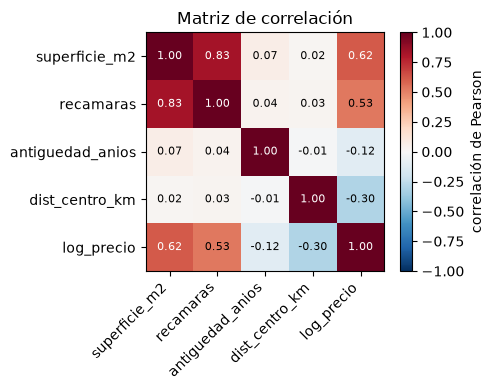

('superficie_m2', 'recamaras') 0.829


In [10]:
cols = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
C = pd.concat([viv[cols], log_precio.rename("log_precio")], axis=1).corr()     #Pearson

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)                        #escala divergente centrada en 0
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=45, ha="right")
ax.set_yticks(range(len(C))); ax.set_yticklabels(C.index)
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(C.values[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="correlación de Pearson")
ax.set_title("Matriz de correlación"); ax.grid(False)
plt.tight_layout(); plt.show()

Cx = C.loc[cols, cols].abs().where(~np.eye(len(cols), dtype=bool))   #sin la diagonal
par = tuple(Cx.stack().idxmax())                                       #par más correlacionado
print(par, round(C.loc[par[0], par[1]], 3))

**Respuesta:**

El par más correlacionado es **`superficie_m2`–`recamaras`** (r = 0.83): más metros, más recámaras. Meter ambas en una regresión lineal produce **multicolinealidad**: los coeficientes se vuelven inestables (varianza inflada, VIF alto), cambian mucho con la muestra y es difícil interpretar el efecto de una “manteniendo la otra fija”. Conservaría `superficie_m2` (más correlacionada con `log_precio`: 0.62 contra 0.53) o crearía una razón como m² por recámara; otra opción es usar regularización (Ridge).

---
## Parte II — Preprocesamiento de datos (35 puntos)

Seguimos con el conjunto `viv`. Ahora el objetivo es **predecir `log(precio_miles)`** con un modelo lineal, cuidando el preprocesamiento.

### Pregunta II.1 · Cuantificar los valores faltantes  *(4 pts)*

Calcula (a) el número y el porcentaje de valores faltantes por columna y (b) la **proporción de faltantes por `zona`** para `antiguedad_anios` y `superficie_m2`.

In [11]:
faltantes = pd.DataFrame({"n": viv.isna().sum(),
                          "%": (100 * viv.isna().mean()).round(2)})          # ✏️  DataFrame con columnas "n" y "%" (una fila por columna de viv)
falt_por_zona = viv[["antiguedad_anios", "superficie_m2"]].isna().groupby(viv["zona"]).mean()   # ✏️ DataFrame: filas = zona, columnas = proporción de NaN en antiguedad_anios y superficie_m2

print(faltantes[faltantes["n"] > 0])
print((100 * falt_por_zona).round(1))

                    n     %
superficie_m2      62  5.17
antiguedad_anios  107  8.92
          antiguedad_anios  superficie_m2
zona                                     
Centro                 2.2            6.7
Costa                  0.0            4.0
Norte                  3.0            4.0
Oriente               19.1            4.4
Poniente               4.4            5.2
Sur                   21.6            6.6


### Pregunta II.2 · Mecanismo de los faltantes  *(3 pts)*

Con lo que observaste en II.1, ¿qué mecanismo (MCAR, MAR o MNAR) es más plausible para `antiguedad_anios` y cuál para `superficie_m2`? Justifica con los números. ¿Qué riesgo habría al **borrar** las filas incompletas?

**Respuesta:**

**`antiguedad_anios`: MAR.** Su proporción de faltantes depende de la zona, que sí observamos: 19.1 % en Oriente y 21.6 % en Sur, contra 0 – 4.4 % en las demás.
**`superficie_m2`: MCAR plausible.** Falta en proporciones parecidas en todas las zonas (4.0 – 6.7 %), sin un patrón.
**Riesgo de borrar:** el detalle con esto es que se perderían 163 filas (siendo un 13.6 %) y, sobre todo, se sesgaría la muestra contra Sur y Oriente (pasan de 17.8 % a 15.0 % y de 15.2 % a 13.8 %), que son zonas más baratas, por lo que, el modelo quedaría sesgado hacia las zonas caras.

### Pregunta II.3 · División entrenamiento / prueba  *(5 pts)*

Define `X = viv` sin `precio_miles` e `y = log_precio`. Separa 80 % para entrenamiento y 20 % para prueba (`random_state=0`) **estratificando por `zona`**, y muestra la proporción de cada zona en `X_train` y `X_test`. En **2 líneas**: ¿por qué conviene estratificar en este conjunto?

In [12]:
X = viv.drop(columns="precio_miles")                                   # ✏️
y = log_precio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=X["zona"])           # ✏️ train_test_split estratificado por zona

prop = pd.DataFrame({"train": X_train["zona"].value_counts(normalize=True),
                     "test":  X_test["zona"].value_counts(normalize=True)})   # ✏️ DataFrame: proporción de cada zona en train y en test
print((100 * prop).round(1))

          train  test
zona                 
Norte      27.4  27.5
Poniente   22.5  22.5
Sur        17.7  17.9
Oriente    15.3  15.0
Centro     15.0  15.0
Costa       2.1   2.1


**Respuesta:**

`zona` afecta mucho al precio y está desbalanceada. **Costa** solo tiene 25 viviendas. Una división aleatoria podría dejar muy pocas o ninguna en prueba, por lo que, estratificando, cada zona conserva su proporción (Costa 2.1 % en ambos), y el error de prueba es representativo de todas las zonas.

### Pregunta II.4 · Detectar fuga de datos  *(4 pts)*

Un compañero escribe este código para “preparar los datos” y luego evalúa con validación cruzada:

```python
X_num = viv[["superficie_m2", "antiguedad_anios", "dist_centro_km"]]
X_num = SimpleImputer(strategy="mean").fit_transform(X_num)      # (1)
X_num = StandardScaler().fit_transform(X_num)                    # (2)
scores = cross_val_score(Ridge(), X_num, log_precio, cv=5)       # (3)
```

Explica **qué información se filtra** en los pasos (1) y (2), por qué es un problema y cómo lo corregirías (en palabras, sin escribir todo el código).

**Respuesta:**

En (1) la **media** con la que se imputa y en (2) la **media y la desviación estándar** del escalador se calculan con **todas** las filas, incluidas las que en cada partición de `cross_val_score` servirán de validación. Así, los datos de validación influyen en cómo se transforman los de entrenamiento: dejan de ser datos “nuevos” y la evaluación sale **optimista** (aquí el efecto sería pequeño, pero el procedimiento es incorrecto y con otros pasos, como la selección de variables, el sesgo es enorme).
**Corrección:** dividir primero en entrenamiento y prueba, y poner imputador, escalador y Ridge en un **`Pipeline`**, pasando a `cross_val_score` los datos **sin preprocesar**. Así, en cada partición el imputador y el escalador se ajustan (`fit`) solo con el entrenamiento y se aplican (`transform`) a la validación.

### Pregunta II.5 · Pipeline de preprocesamiento + modelo  *(10 pts)*

Construye un `Pipeline` que, **sin fuga de datos**, haga:

1. Variables numéricas (`superficie_m2`, `recamaras`, `antiguedad_anios`, `dist_centro_km`): imputación y un escalador de tu elección.
2. Variable nominal `zona`: imputación (por si acaso) y codificación *one-hot* **tolerante a categorías no vistas**.
3. Variable ordinal `acabados`: codificación ordinal respetando Básico < Medio < Alto < Premium.
4. Modelo: `Ridge(alpha=1.0)`.

Evalúa con validación cruzada de 5 particiones **solo con el entrenamiento** (reporta el RMSE medio sobre `log(precio)`), ajusta con todo el entrenamiento y reporta el RMSE en prueba. Justifica en 2 líneas tu elección de imputador y escalador.

In [13]:
NUM_X = ["superficie_m2", "recamaras", "antiguedad_anios", "dist_centro_km"]
NOM = ["zona"]
ORD = ["acabados"]

num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])                                   # ✏️ Pipeline: imputación + escalado
nom_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore"))])             # ✏️ Pipeline: imputación + one-hot (maneja categorías no vistas)
ord_pipe = OrdinalEncoder(categories=[["Básico", "Medio", "Alto", "Premium"]])        # ✏️ codificador ordinal con el orden correcto
pre = ColumnTransformer([("num", num_pipe, NUM_X),
                         ("nom", nom_pipe, NOM),
                         ("ord", ord_pipe, ORD)])                                     # ✏️ une los tres tratamientos
modelo = Pipeline([("pre", pre), ("ridge", Ridge(alpha=1.0))])                        # ✏️ Pipeline(preprocesamiento + Ridge)

cv = KFold(5, shuffle=True, random_state=0)
rmse_cv = -cross_val_score(modelo, X_train, y_train, cv=cv,
                           scoring="neg_root_mean_squared_error").mean()             # ✏️ RMSE medio en validación cruzada (usa solo X_train, y_train)
modelo.fit(X_train, y_train)
rmse_test = np.sqrt(mean_squared_error(y_test, modelo.predict(X_test)))              # ✏️ ajusta con X_train, y_train y evalúa en X_test, y_test

print(f"RMSE CV = {rmse_cv:.3f}    RMSE prueba = {rmse_test:.3f}")

RMSE CV = 0.254    RMSE prueba = 0.251


**Respuesta:**

**Imputador: mediana**, porque `superficie_m2` y `antiguedad_anios` son asimétricas (1 y 1.41) y la mediana es robusta a sus colas. **Escalador: `StandardScaler`**, porque Ridge penaliza el tamaño de los coeficientes y necesita variables en escala comparable; es la opción estándar y aquí no hay atípicos extremos en las explicativas. El RMSE de validación (0.254) y el de prueba (0.251) son casi iguales, el modelo generaliza bien.

### Pregunta II.6 · Escalador y atípicos  *(4 pts)*

Toma `superficie_m2` del conjunto de entrenamiento (imputando antes los `NaN` con la mediana) y **añade un registro mal capturado de 5 000 m²**. Aplica `StandardScaler` y `RobustScaler`. Para cada resultado calcula el **rango intercuartílico** de la variable escalada y su **valor absoluto máximo**. En **2 a 3 líneas**: ¿qué escalador es más sensible a los atípicos y por qué? ¿Para qué tipo de modelos importa escalar?

In [14]:
s = X_train["superficie_m2"].fillna(X_train["superficie_m2"].median())
s = pd.concat([s, pd.Series([5000.0])], ignore_index=True).to_frame()     # añadimos el dato mal capturado

z_std = StandardScaler().fit_transform(s).ravel()      # ✏️ s escalada con StandardScaler (array 1D)
z_rob = RobustScaler().fit_transform(s).ravel()        # ✏️ s escalada con RobustScaler  (array 1D)

def resumen(z):
    q1, q3 = np.percentile(z, [25, 75])
    return {"IQR": round(q3 - q1, 3), "|max|": round(np.abs(z).max(), 2)}

print("Standard:", resumen(z_std))
print("Robust:  ", resumen(z_rob))

Standard: {'IQR': np.float64(0.354), '|max|': np.float64(29.78)}
Robust:   {'IQR': np.float64(1.0), '|max|': np.float64(84.28)}


**Respuesta:**

**`StandardScaler` es más sensible:** el dato de 5,000 m² infla la desviación estándar, así que todas las viviendas normales quedan **comprimidas** en una franja angosta (IQR de 0.35). **`RobustScaler`** usa mediana e IQR, que el atípico casi no mueve, el grueso conserva su escala (IQR = 1) y el error de captura queda claramente separado. Escalar importa en modelos basados en **distancias** (KNN, SVM, k-means), **regularizados** (Ridge, Lasso) y de **gradiente** (redes); a los árboles no les afecta.

### Pregunta II.7 · Categorías no vistas y codificación  *(5 pts)*

Ajusta un `OneHotEncoder` **con el valor por defecto** y otro con `handle_unknown="ignore"` usando solo las filas de `X_train` cuya `zona` **no** sea `Costa`. Luego transforma una vivienda de `Costa` con cada uno: captura el error del primero (`msg_error`) y guarda la fila resultante del segundo (`fila_ignore`).
En **2 líneas**: ¿qué problema aparece si en lugar de *one-hot* codificas `zona` con enteros (0, 1, 2, …) en un modelo lineal?

In [15]:
sin_costa = X_train.loc[X_train["zona"] != "Costa", ["zona"]]
nueva = pd.DataFrame({"zona": ["Costa"]})

msg_error = None
try:
    OneHotEncoder().fit(sin_costa).transform(nueva)        # ✏️ OneHotEncoder() por defecto: ajustar con sin_costa y transformar nueva
except ValueError as e:
    msg_error = str(e)[:90]

enc_ign = OneHotEncoder(handle_unknown="ignore").fit(sin_costa)
fila_ignore = enc_ign.transform(nueva).toarray()        #✏️ OneHotEncoder(handle_unknown="ignore"): ajustar y transformar nueva (array denso)
print("Categorías aprendidas:", list(enc_ign.categories_[0]))

print("Error:", msg_error)
print("Fila con ignore:", fila_ignore)

Categorías aprendidas: ['Centro', 'Norte', 'Oriente', 'Poniente', 'Sur']
Error: Found unknown categories ['Costa'] in column 0 during transform
Fila con ignore: [[0. 0. 0. 0. 0.]]


**Respuesta:**

Con enteros, el modelo lineal interpreta `zona` como una variable **numérica con orden y distancias** que no existen (p. ej. Sur = 4 estaría “el doble de lejos” que Centro = 2) y le asigna **una sola pendiente**, forzando un efecto lineal sobre un orden arbitrario (alfabético). One-hot da un coeficiente propio a cada zona. Nota: con `handle_unknown="ignore"`, Costa queda como `[0, 0, 0, 0, 0]` (“ninguna zona conocida”) en vez de provocar el error.

---
## Parte III — Ingeniería y selección de variables (35 puntos)

Ahora `X_b` contiene **26 mediciones de laboratorio** de 400 pacientes y `y_b` es un diagnóstico binario (0/1). Algunas variables
son útiles y otras no. Toda evaluación de desempeño debe hacerse con **validación cruzada** (`cv_b`) y, cuando haya selección o
escalado, **dentro de un `Pipeline`**.

In [16]:
X_b, y_b = genera_biomarcadores()
cv_b = StratifiedKFold(5, shuffle=True, random_state=0)
print(X_b.shape, y_b.value_counts().to_dict())

(400, 26) {1: 213, 0: 187}


### Pregunta III.1 · Umbral de varianza  *(5 pts)*

Aplica `VarianceThreshold(threshold=0.01)` a `X_b` en su escala original y guarda en `quitadas_crudo` la lista de variables eliminadas. Repite con `X_b` estandarizada y guarda en `n_quitadas_std` cuántas elimina. En **3 líneas**: ¿qué enseñan los dos resultados sobre el umbral de varianza como criterio de selección?

In [17]:
vt = VarianceThreshold(threshold=0.01).fit(X_b)
quitadas_crudo = list(X_b.columns[~vt.get_support()])                       # ✏️ escala original

X_b_std = StandardScaler().fit_transform(X_b)
n_quitadas_std = int((~VarianceThreshold(threshold=0.01).fit(X_b_std).get_support()).sum())   # ✏️ estandarizada

print("Original:", quitadas_crudo)
print("Estandarizada:", n_quitadas_std)
print("Varianzas originales (las 6 menores):"); print(X_b.var(ddof=0).sort_values().head(6))

Original: ['lin_c', 'casi_const']
Estandarizada: 0
Varianzas originales (las 6 menores):
casi_const    0.000001
lin_c         0.000731
ruido_18      0.821288
ruido_07      0.901922
ruido_15      0.939772
ruido_09      0.944859
dtype: float64


**Respuesta:**

En escala original se eliminan `lin_c` y `casi_const`; pero **`lin_c` sí es informativa** (está entre las 5 mejores por F y por información mutua): solo tiene varianza pequeña por sus **unidades** (×0.02). Tras estandarizar, todas valen varianza 1 y el filtro **no elimina nada**, ni siquiera `casi_const`. El umbral de varianza depende de la escala y no mira el objetivo; solo sirve para detectar columnas constantes o casi constantes, no como criterio de relevancia.

### Pregunta III.2 · Filtros: F de ANOVA vs. información mutua  *(6 pts)*

Selecciona las 5 mejores variables con `SelectKBest` usando (a) `f_classif` y (b) `mutual_info_classif` (con `random_state=0`). Guarda los nombres en `sel_F` y `sel_MI`. En **3 a 4 líneas**: ¿qué variable distingue ambos resultados y por qué un filtro la ve y el otro no? (Pista: calcula la correlación de Pearson de esa variable con `y_b`.)

In [18]:
from functools import partial
sel_F = list(X_b.columns[SelectKBest(f_classif, k=5).fit(X_b, y_b).get_support()])          # ✏️
mi = partial(mutual_info_classif, random_state=0)
sel_MI = list(X_b.columns[SelectKBest(mi, k=5).fit(X_b, y_b).get_support()])                # ✏️

print("F :", sel_F)
print("MI:", sel_MI)
print("r de Pearson de cuad con y_b:", round(X_b["cuad"].corr(y_b), 3))
print("Media de |cuad| por clase:", X_b["cuad"].abs().groupby(y_b).mean().round(2).to_dict())

F : ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia', 'ruido_08']
MI: ['lin_a', 'lin_b', 'lin_c', 'cuad', 'lin_a_copia']
r de Pearson de cuad con y_b: -0.024
Media de |cuad| por clase: {0: 0.36, 1: 1.55}


**Respuesta:**

La diferencia es **`cuad`** (la elige MI) frente a `ruido_08` (la elige F, por azar). Su correlación con `y_b` es −0.02 en la clase 1, `cuad` toma valores  ±1.6 con signo al azar, así que su **media es ≈ 0 en ambas clases** y el F de ANOVA (diferencia de medias, relación lineal) no ve nada. Pero la **magnitud** sí cambia (|cuad| promedio 1.55 contra 0.36) es una relación en U. La información mutua mide **cualquier dependencia**, no solo la lineal, y por eso la detecta.

### Pregunta III.3 · Redundancia  *(4 pts)*

Calcula la matriz de correlación de las variables de `sel_MI` y guarda en `par_redundante` el par con mayor correlación absoluta. En **2 líneas**: ¿por qué un filtro univariado no evita este problema y qué harías al respecto?

In [19]:
R = X_b[sel_MI].corr()                                                   # ✏️ matriz de correlación de X_b[sel_MI]
Ra = R.abs().where(~np.eye(len(R), dtype=bool))                         
par_redundante = tuple(Ra.stack().idxmax())                              # ✏️ tupla (var1, var2) con mayor |correlación| fuera de la diagonal
print(par_redundante, round(abs(R.loc[par_redundante[0], par_redundante[1]]), 3))

('lin_a', 'lin_a_copia') 0.994


**Respuesta:**

El par es **`lin_a`–`lin_a_copia`** (|r| ≈ 0.994): son casi la misma variable. Un filtro univariado puntúa cada variable **por separado** frente a `y`; como ambas se relacionan mucho con `y`, las dos puntúan alto, sin ver que repiten la misma información. Quitaría una de cada par con |r| > 0.9 (conservando la más relacionada con `y`) o usaría un método multivariado.

### Pregunta III.4 · Envoltura: RFE y RFECV  *(6 pts)*

Con regresión logística (`max_iter=1000`) y **estandarizando dentro del pipeline**:
(a) usa `RFE` para conservar 6 variables y guarda sus nombres en `sel_rfe`;
(b) usa `RFECV` (con `cv_b` y `scoring="accuracy"`) y guarda en `k_opt` el número de variables que recomienda.
En **3 líneas**: ¿`RFE` con regresión logística recupera `cuad`? ¿Por qué? ¿Qué costo tiene frente a un filtro?

In [20]:
pipe_rfe = Pipeline([("sc", StandardScaler()),
                     ("rfe", RFE(LogisticRegression(max_iter=1000), n_features_to_select=6))])   
pipe_rfe.fit(X_b, y_b)
sel_rfe = list(X_b.columns[pipe_rfe.named_steps["rfe"].support_])                              

pipe_cv = Pipeline([("sc", StandardScaler()),
                    ("rfecv", RFECV(LogisticRegression(max_iter=1000), cv=cv_b, scoring="accuracy"))])  
pipe_cv.fit(X_b, y_b)
k_opt = int(pipe_cv.named_steps["rfecv"].n_features_)                                          
print("k óptimo:", k_opt)
print("Elegidas por RFECV:", list(X_b.columns[pipe_cv.named_steps["rfecv"].support_]))

k óptimo: 4
Elegidas por RFECV: ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia']


**Respuesta:**

**No recupera `cuad`.** RFE ordena por el |coeficiente| del modelo, y la regresión logística solo capta relaciones lineales/monótonas: como la relación de `cuad` con `y` es en U, su coeficiente es ≈ 0 y se elimina pronto. (De hecho, eligió dos variables de ruido y conservó a la vez `lin_a` y su copia.) RFECV recomienda **4** variables: las cuatro lineales. **Costo:** RFE reentrena el modelo una vez por cada variable eliminada (y RFECV, además, en cada partición), es mucho más caro que un filtro que calcula una puntuación por variable en una sola pasada.

### Pregunta III.5 · Selección integrada: regresión logística L1  *(4 pts)*

Para $C \in \{0.005,\,0.01,\,0.05,\,0.1,\,1\}$, ajusta `LogisticRegression(penalty="l1", solver="liblinear", C=C)` sobre `X_b` estandarizada, usando `SelectFromModel`, y guarda en `n_sel` un dict `{C: número de variables seleccionadas}`. En **2 líneas**: ¿cómo se relaciona $C$ con el número de variables y qué ventaja tiene este método frente a un filtro?

In [21]:
n_sel = {}
for C in [0.005, 0.01, 0.05, 0.1, 1]:
    p = Pipeline([("sc", StandardScaler()),
                  ("sel", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=C)))]).fit(X_b, y_b)
    n_sel[C] = int(p.named_steps["sel"].get_support().sum())          # ✏️ Pipeline(StandardScaler + SelectFromModel(LogisticRegression L1)) y cuenta las seleccionadas
    print(C, list(X_b.columns[p.named_steps["sel"].get_support()]))
print(n_sel)

0.005 []
0.01 ['lin_a', 'lin_c']
0.05 ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia']
0.1 ['lin_a', 'lin_b', 'lin_c', 'lin_a_copia']
1 ['lin_a', 'lin_b', 'lin_c', 'cuad', 'casi_const', 'ruido_01', 'ruido_03', 'ruido_04', 'ruido_05', 'ruido_06', 'ruido_07', 'ruido_08', 'ruido_09', 'ruido_10', 'ruido_11', 'ruido_12', 'ruido_13', 'ruido_14', 'ruido_15', 'ruido_16', 'ruido_18', 'ruido_19', 'ruido_20']
{0.005: 0, 0.01: 2, 0.05: 4, 0.1: 4, 1: 23}


**Respuesta:**

$C = 1/\alpha$: **a menor $C$, más penalización y menos variables** (0, 2, 4, 4 y 23 variables para $C$ = 0.005, 0.01, 0.05, 0.1 y 1). Ventaja frente a un filtro: selecciona **mientras ajusta el modelo**, considerando las variables en conjunto (con $C$ = 0.05 descarta todo el ruido y `casi_const`), y $C$ puede elegirse por validación cruzada.

### Pregunta III.6 · Fuga de datos en la selección de variables  *(6 pts)*

Generamos datos de **puro ruido**: `Xn` con 100 filas y 1 000 columnas aleatorias, y `yn` aleatoria; por construcción, ningún modelo puede predecir `yn` mejor que el azar (exactitud ≈ 0.5).

(a) **Mal:** selecciona las 20 mejores columnas con `SelectKBest(f_classif)` usando *todos* los datos y luego evalúa una regresión logística con validación cruzada → `acc_mal`.
(b) **Bien:** pon la selección y el modelo en un `Pipeline` y evalúa con la misma validación cruzada → `acc_bien`.
En **3 líneas**: explica la diferencia y qué regla de la receta de selección se viola en (a).

In [22]:
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 1000))
yn = rng.integers(0, 2, 100)
cv_n = StratifiedKFold(5, shuffle=True, random_state=0)     

# (a) MAL: la selección ve las etiquetas de todas las filas antes de validar
Xn_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
acc_mal = cross_val_score(LogisticRegression(max_iter=1000), Xn_sel, yn, cv=cv_n).mean()       # ✏️

# (b) BIEN: la selección se repite dentro de cada partición
pipe_ok = Pipeline([("sel", SelectKBest(f_classif, k=20)), ("lr", LogisticRegression(max_iter=1000))])
acc_bien = cross_val_score(pipe_ok, Xn, yn, cv=cv_n).mean()                                     # ✏️
print(f"Mal: {acc_mal:.2f}    Bien: {acc_bien:.2f}")

Mal: 0.85    Bien: 0.57


**Respuesta:**

En (a) `SelectKBest` usó las etiquetas de **todas** las filas, incluidas las que luego sirven de validación: entre 1,000 columnas de ruido eligió las 20 que coinciden por azar con esas etiquetas, y la validación cruzada “confirma” un patrón inexistente (0.85). En (b) la selección se rehace dentro de cada partición solo con el entrenamiento, y la exactitud vuelve a niveles de azar (0.57, ≈ 0.5 con algo de variación por tener solo 100 filas). Se viola la regla **seleccionar es aprender de los datos; debe ir dentro del `Pipeline` y de la validación cruzada (fit solo con el entrenamiento)**.

### Pregunta III.7 · Ingeniería de variables y polinomios  *(4 pts)*

(a) Agrega a `X_b` la variable `cuad_2 = cuad**2`, y compara la exactitud media (CV con `cv_b`) de una regresión logística estandarizada **sin** y **con** la nueva variable (`acc_base`, `acc_nueva`).
(b) Sin ejecutar código, ¿cuántas columnas produce `PolynomialFeatures(degree=3, include_bias=False)` sobre 10 variables? Guarda tu cálculo (fórmula) en `n_poly` y **verifícalo** con scikit-learn. En **1 línea**: ¿qué riesgo implica esta “explosión” de columnas?

In [23]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

acc_base = cross_val_score(lr, X_b, y_b, cv=cv_b).mean()                                   # ✏️
acc_nueva = cross_val_score(lr, X_b.assign(cuad_2=X_b["cuad"] ** 2), y_b, cv=cv_b).mean()  # ✏️ (X_b no se modifica)
print(f"Base: {acc_base:.3f}    Con cuad_2: {acc_nueva:.3f}")

from math import comb
n_poly = comb(10 + 3, 3) - 1                                                                # ✏️ C(n+d, d) - 1
n_poly_sk = PolynomialFeatures(degree=3, include_bias=False).fit(np.zeros((1, 10))).n_output_features_   # ✏️
print(n_poly, n_poly_sk)

Base: 0.903    Con cuad_2: 0.968
285 285


**Respuesta:**

**(a)** Con `cuad_2` la exactitud sube de 0.903 a **0.968**: la relación en U de `cuad` se vuelve lineal al elevarla al cuadrado, y así la regresión logística puede usarla. 

**(b)** $\binom{10+3}{3} - 1 = 285$ columnas, confirmado con scikit-learn. **Riesgo:** con tantas columnas el modelo puede **sobreajustar** (además de ser más costoso y menos interpretable), por lo que hay que regularizar o seleccionar variables.

---
**Fin del examen.** Reinicia el kernel, ejecuta todo el notebook y verifica que corra sin errores antes de entregar.